# Notebook 4 — Multi-Layer Perceptron on Tabular Data (R4)
Rice Variety Classification | F20DL 2026/2027

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay

torch.manual_seed(42)
np.random.seed(42)

df = pd.read_csv('../data/tabular/rice_cammeo_osmancik.csv')
feature_names = [c for c in df.columns if c != 'Class']
X = df[feature_names].values.astype(np.float32)
le = LabelEncoder()
y = le.fit_transform(df['Class']).astype(np.int64)
CLASS_NAMES = list(le.classes_)

# 70% train, 15% val, 15% test
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42, stratify=y_tmp)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val   = scaler.transform(X_val).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)

def make_loader(X, y, shuffle=False):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y))
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

train_dl = make_loader(X_train, y_train, shuffle=True)
val_dl   = make_loader(X_val,   y_val)
test_dl  = make_loader(X_test,  y_test)

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Using device: {device}')
print(f'Train: {len(X_train)}  Val: {len(X_val)}  Test: {len(X_test)}')

Using device: mps
Train: 2667  Val: 571  Test: 572


## 1. Define MLP

In [2]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, output_dim):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(0.3)]
            prev = h
        layers.append(nn.Linear(prev, output_dim))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

model = MLP(input_dim=7, hidden_dims=[64, 32], output_dim=2).to(device)
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=2, bias=True)
  )
)


## 2. Train

In [3]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

EPOCHS = 100
train_losses, val_losses, val_accs = [], [], []
best_val_acc, best_state = 0, None

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    train_losses.append(epoch_loss / len(train_dl))

    model.eval()
    v_loss, correct = 0, 0
    with torch.no_grad():
        for xb, yb in val_dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            v_loss += criterion(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
    val_losses.append(v_loss / len(val_dl))
    val_accs.append(correct / len(X_val))
    scheduler.step(val_losses[-1])

    if val_accs[-1] > best_val_acc:
        best_val_acc = val_accs[-1]
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

    if (epoch + 1) % 20 == 0:
        print(f'Epoch {epoch+1:3d}: train_loss={train_losses[-1]:.4f}  val_loss={val_losses[-1]:.4f}  val_acc={val_accs[-1]:.4f}')

print(f'\nBest val accuracy: {best_val_acc:.4f}')
model.load_state_dict(best_state)

Epoch  20: train_loss=0.1867  val_loss=0.2183  val_acc=0.9159


Epoch  40: train_loss=0.1829  val_loss=0.2153  val_acc=0.9194


Epoch  60: train_loss=0.1824  val_loss=0.2161  val_acc=0.9194


Epoch  80: train_loss=0.1870  val_loss=0.2161  val_acc=0.9194


Epoch 100: train_loss=0.1860  val_loss=0.2161  val_acc=0.9194

Best val accuracy: 0.9212


<All keys matched successfully>

## 3. Evaluate & Plot

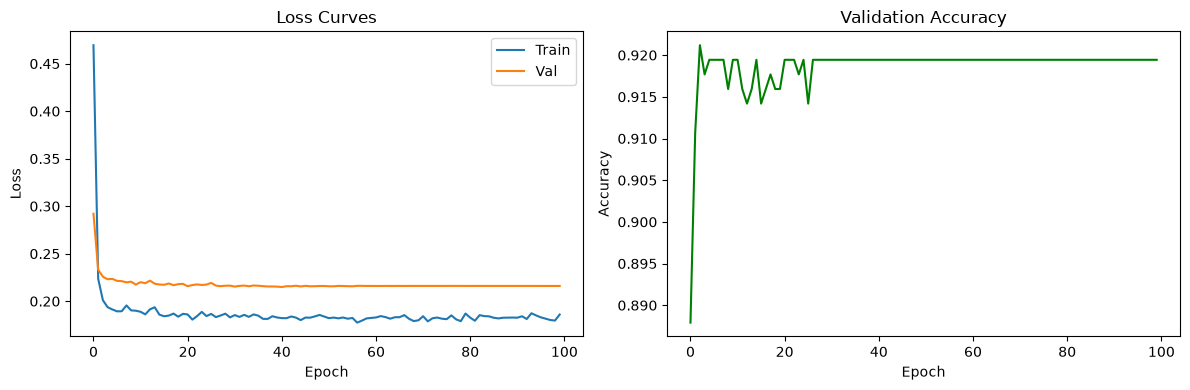

              precision    recall  f1-score   support

      Cammeo       0.92      0.90      0.91       245
    Osmancik       0.92      0.94      0.93       327

    accuracy                           0.92       572
   macro avg       0.92      0.92      0.92       572
weighted avg       0.92      0.92      0.92       572



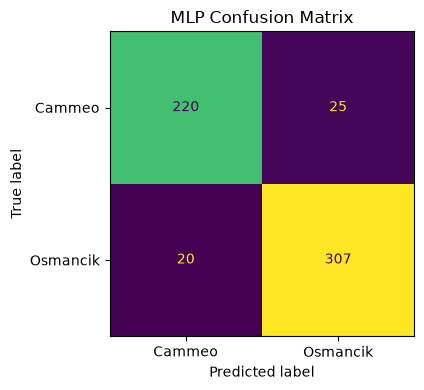


MLP Test Accuracy: 0.9213  F1: 0.9212


In [4]:
# Learning curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(train_losses, label='Train')
ax1.plot(val_losses, label='Val')
ax1.set(title='Loss Curves', xlabel='Epoch', ylabel='Loss')
ax1.legend()
ax2.plot(val_accs, color='green')
ax2.set(title='Validation Accuracy', xlabel='Epoch', ylabel='Accuracy')
plt.tight_layout()
plt.savefig('../results/mlp_training.png', dpi=100)
plt.show()

# Test evaluation
model.eval()
all_preds = []
with torch.no_grad():
    for xb, _ in test_dl:
        all_preds.extend(model(xb.to(device)).argmax(1).cpu().numpy())

print(classification_report(y_test, all_preds, target_names=CLASS_NAMES))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, all_preds, display_labels=CLASS_NAMES, ax=ax, colorbar=False)
ax.set_title('MLP Confusion Matrix')
plt.tight_layout()
plt.savefig('../results/mlp_confusion.png', dpi=100)
plt.show()

mlp_acc = accuracy_score(y_test, all_preds)
mlp_f1  = f1_score(y_test, all_preds, average='weighted')
print(f'\nMLP Test Accuracy: {mlp_acc:.4f}  F1: {mlp_f1:.4f}')
torch.save(model.state_dict(), '../models/mlp.pt')

## 4. MLP vs Baseline Comparison

                     Accuracy  Precision  Recall      F1
MLP                    0.9213     0.9212  0.9212  0.9212
Decision Tree          0.9199     0.9210  0.9199  0.9195
Logistic Regression    0.9186     0.9189  0.9186  0.9183
Random Forest          0.9160     0.9164  0.9160  0.9157
Gradient Boosting      0.9147     0.9149  0.9147  0.9144
kNN                    0.9121     0.9120  0.9121  0.9119
Perceptron             0.8990     0.8988  0.8990  0.8988
Naive Bayes            0.8950     0.8953  0.8950  0.8945


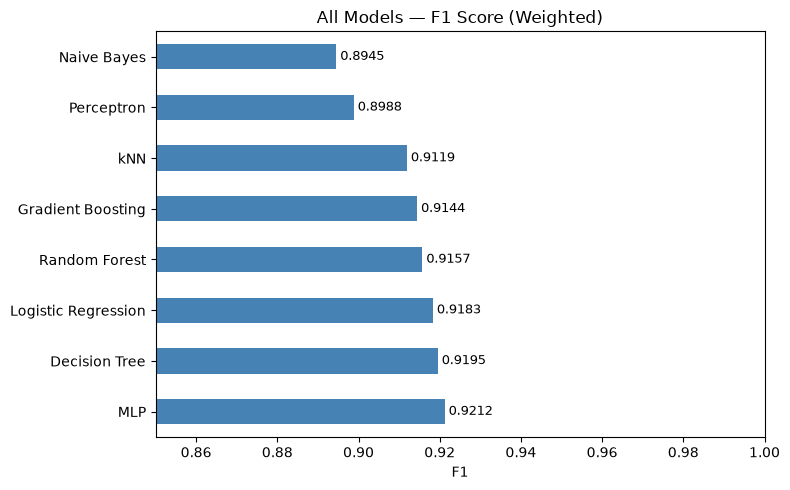

In [5]:
baseline = pd.read_csv('../results/baseline_comparison.csv', index_col=0)
mlp_row = pd.DataFrame({'Accuracy': mlp_acc, 'Precision': mlp_f1, 'Recall': mlp_f1, 'F1': mlp_f1}, index=['MLP'])
comparison = pd.concat([baseline, mlp_row]).sort_values('F1', ascending=False).round(4)
print(comparison.to_string())
comparison.to_csv('../results/full_comparison.csv')

ax = comparison['F1'].plot(kind='barh', figsize=(8, 5), color='steelblue')
ax.set(title='All Models — F1 Score (Weighted)', xlabel='F1', xlim=(0.85, 1.0))
for bar in ax.patches:
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{bar.get_width():.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('../results/full_model_comparison.png', dpi=100)
plt.show()